# Olivia Gallagher, Yamini Sirobushanam, Zoe Scherrer

# Case 2: Choosing a Demand Model for a Subscription Price Test

**Your role:** analytics candidate for a digital subscription business  
**Decision maker:** vice president for growth and pricing  
**Data:** `case02_subscription_price_experiment.csv`, 480 local markets

## Brief

The company ran a price test. Each of 480 local markets was randomly assigned one of four monthly prices, \$7.99, \$9.99, \$11.99 or \$13.99, and the company counted how many eligible visitors subscribed. The growth team wants a single demand curve for scenario planning and is considering a move to \$15 a month, a price that was not tested. A model with the highest in-sample R-squared may predict badly at an untested price. Your recommendation must balance fit, economic sense, and the fact that only four prices were tested.

**Management question:** Which simple demand curve should the company use to summarize its price test and predict subscriptions at nearby prices?

## Data dictionary

| Variable | Units or type | Meaning |
|---|---|---|
| `market_id` | Identifier | One local market. Each market appears once in the price test. |
| `assigned_price_usd` | US dollars per month | Randomly assigned subscription price: 7.99, 9.99, 11.99 or 13.99. |
| `eligible_visitors` | Count | Visitors eligible to see the offer during the price test. |
| `new_subscriptions` | Count | New subscriptions during the price test. |
| `subscriptions_per_1000` | Rate | New subscriptions divided by eligible visitors, times 1,000. |
| `analysis_sample` | Category | `train` or `test`, fixed in advance. Do not use the test markets to choose a model. |

**Revenue per 1,000 visitors** is the price times subscriptions per 1,000 visitors: the first month's revenue, in dollars, from 1,000 eligible visitors.

## Submission

- Before you submit, restart the kernel and run all cells. The notebook must run from top to bottom without errors.
- Submit the notebook twice: the .ipynb file and a PDF export with all code and output readable.

In [1]:
# Starter code: run this cell first and do not edit it.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

#my pathway to data
import os
os.getcwd()
os.chdir('/Users/livigallagher/Econometrics/Lab/Lab Data')

# The price-test data, exactly as received. Leave raw unchanged.
raw = pd.read_csv('case02_subscription_price_experiment.csv')
raw.head()

,market_id,assigned_price_usd,eligible_visitors,new_subscriptions,subscriptions_per_1000,analysis_sample
0,MKT0001,13.99,9026,202,22.3798,test
1,MKT0002,11.99,9812,329,33.5304,train
2,MKT0003,9.99,7644,154,20.1465,train
3,MKT0004,7.99,6830,322,47.1449,train
4,MKT0005,11.99,10507,247,23.5081,train


## Stage 1. Frame the decision

Each market's price was set by random assignment, not chosen by the company or by the market.

- 1. What does random assignment let you conclude when you compare subscriptions in markets at two different tested prices?
- 2. Name one thing that could go wrong when a price test like this is carried out, and that would weaken that conclusion.
- 3. Why is a prediction at \$15 a different kind of claim from a comparison of two tested prices?

**Output:** three or four sentences.

**Answer:**
1. Random assignment lets us conclude that there is no selection bias driving/influencing our results. This will help the internal validity of our study.

2. When a price test like this is carried out, we have to worry about consumers in one market seeing the prices from a different market. If they see another consumer paying less than they are for the exact same product, they are very unlikely to purchase the product. This will give us false negatives. 

3. Prediction at 15 dollars is different from a comparison of two tested prices because 15 dollars was never tested itself- we are making a claim on a number outside of our dataset. Instead of estimating, we are predicting. 

## Stage 2. Check the file and the experiment

Before you look at how many visitors subscribed, check that the file matches the data dictionary and that the price test ran as designed.

- 1. Check that each market appears once and that no values are missing.
- 2. Count the markets assigned to each price.
- 3. Compare the number of eligible visitors per market across the four price groups.
- 4. Compare any differences between the groups with how much visitors vary within a group.
- 5. If prices were assigned by chance, what should you see?
- 6. Recompute subscriptions per 1,000 from `new_subscriptions` and `eligible_visitors`, and check that it matches the stored rate, which is rounded to four decimals.
- 7. Does every market have at least one new subscription? Why does that matter for a model in logs?
- 8. Store the training markets as `train` and the test markets as `test`. From here on, use `train` only; a later stage uses `test` once.

**Output:** a short data audit, with the number of markets in `train` and in `test`.

In [2]:
#1. checking each market appears once (dropping duplicates)
df = pd.read_csv('case02_subscription_price_experiment.csv')
df[df.duplicated()]
df = df.drop_duplicates(subset='market_id', keep='first')
df.shape

(480, 6)

In [3]:
#1. checking missing values
df.isna().sum()
df = df.dropna()
df.shape

(480, 6)

In [4]:
#2. count markets assigned to each price
df.groupby('assigned_price_usd')['market_id'].count()

assigned_price_usd
7.99     124
9.99     107
11.99    130
13.99    119
Name: market_id, dtype: int64

In [5]:
#3. Compare the number of eligible visitors per market across the four price groups.
df.groupby('assigned_price_usd')['eligible_visitors'].sum()

assigned_price_usd
7.99     1092418
9.99      926701
11.99    1117958
13.99     986105
Name: eligible_visitors, dtype: int64

In [6]:
#4. Compare any differences between the groups with how much visitors vary within a group (min)
df.groupby('assigned_price_usd')['eligible_visitors'].min()

assigned_price_usd
7.99     3521
9.99     3664
11.99    3522
13.99    3628
Name: eligible_visitors, dtype: int64

In [7]:
#4. Compare any differences between the groups with how much visitors vary within a group (max)
df.groupby('assigned_price_usd')['eligible_visitors'].max()

assigned_price_usd
7.99     13870
9.99     13963
11.99    13942
13.99    13956
Name: eligible_visitors, dtype: int64

**#4 answer**: Visitors do not vary much by group. The minimum number of visitors among markets is around 3550 and the maximum is around 13900. These numbers are consistent among markets.

**#5 answer:** If prices were assigned by chance, I would expect to see similarities among the groups. Statistically, the groups should look almost the same with minimal differences in averages, range, standard deviation, etc. Any differences that we do see are attributed to random chance.

In [8]:
#6. first, find what the stored rate is
df.describe().round(4)
#mean is 29.7659

,assigned_price_usd,eligible_visitors,new_subscriptions,subscriptions_per_1000
count,480.0000,480.0000,480.0000,480.0000
mean,11.0067,8589.9625,257.5708,29.7659
std,2.2495,3115.4077,135.4157,9.8813
min,7.9900,3521.0000,47.0000,12.0020
25%,7.9900,5919.7500,158.0000,22.0701
50%,11.9900,8705.0000,231.0000,27.4224
75%,11.9900,11370.7500,327.5000,36.4191
max,13.9900,13963.0000,837.0000,60.5075


In [9]:
#6. Recompute subscriptions per 1,000 from new_subscriptions and eligible_visitors, and check that it matches the stored rate, which is rounded to four decimals.
rate_check = (df.new_subscriptions / df.eligible_visitors) * 1000
print(rate_check)
rate_check.mean()

0      22.379792
1      33.530371
2      20.146520
3      47.144949
4      23.508137
         ...    
475    25.501735
476    22.189887
477    44.515741
478    26.866284
479    27.515047
Length: 480, dtype: float64


np.float64(29.765886899375985)

**#6 answer:** Our rate is 29.7659 which matches the stored value.

In [10]:
#7. Does every market have at least one new subscription?
df.groupby('market_id')['new_subscriptions'].any()

market_id
MKT0001    True
MKT0002    True
MKT0003    True
MKT0004    True
MKT0005    True
           ... 
MKT0476    True
MKT0477    True
MKT0478    True
MKT0479    True
MKT0480    True
Name: new_subscriptions, Length: 480, dtype: bool

**#7. answer:** Yes, each market has at least one new subscription, represented by "true" in the boolean stat.

In [11]:
#8. Store the training markets as `train` and the test markets as `test`
#using copy so we can add the revenue variable from stage 3 part 2 without modifying the original df
df_train = df[df['analysis_sample'] == 'train'].copy()
df_test = df[df['analysis_sample'] == 'test'].copy()
df_train.head() #double check they sorted correctly

,market_id,assigned_price_usd,eligible_visitors,new_subscriptions,subscriptions_per_1000,analysis_sample
1,MKT0002,11.99,9812,329,33.5304,train
2,MKT0003,9.99,7644,154,20.1465,train
3,MKT0004,7.99,6830,322,47.1449,train
4,MKT0005,11.99,10507,247,23.5081,train
6,MKT0007,9.99,6776,208,30.6966,train


## Stage 3. Read the experiment

Use `train` only.

- 1. Make one figure that shows each market's subscriptions per 1,000 at its assigned price, together with the mean of each price group and its 95% confidence interval.
- 2. Make a table with one row per price: the number of markets, the mean subscriptions per 1,000, and the mean revenue per 1,000 visitors.
- 3. Each step in the price test raises the price by \$2. Does each step cost about the same number of subscriptions per 1,000? Use your table.
- 4. How does the spread of markets around their group's mean change as price rises?
- 5. Which tested price brings in the most revenue per 1,000 visitors?

**Output:** one figure, one table, and a short description of the demand pattern.

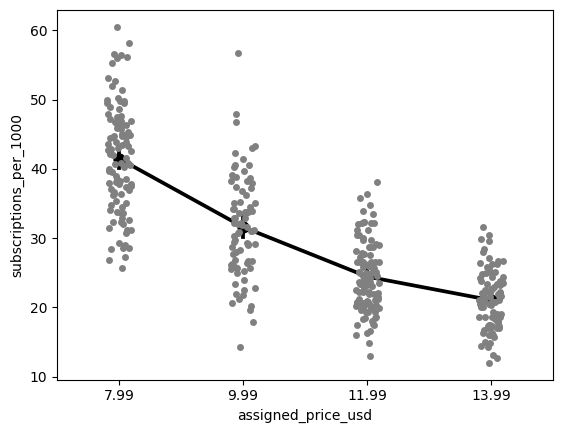

In [12]:
#1. group mean figure
sns.stripplot(data=df_train, x='assigned_price_usd', y='subscriptions_per_1000', color='gray', alpha=1)
sns.pointplot(data=df_train, x='assigned_price_usd', y='subscriptions_per_1000', color='black')
plt.show()

In [13]:
#2. Table with one row per price: the number of markets, the mean subscriptions per 1,000, and the mean revenue per 1,000 visitors.

#calc revenue:
df_train['revenue'] = (df_train['assigned_price_usd'] * df_train['subscriptions_per_1000'])

#make table
table = df_train.groupby('assigned_price_usd').agg(
    total_markets=('market_id', 'count'),
    mean_subs=('subscriptions_per_1000', 'mean'),
    mean_rev=('revenue', 'mean'))

print(table)

                    total_markets  mean_subs    mean_rev
assigned_price_usd                                      
7.99                          103  41.478031  331.409468
9.99                           82  31.602328  315.707257
11.99                         109  24.447506  293.125591
13.99                          90  21.038509  294.328739


**#3 Answer:** No, each 2 dollar increase does not cost the same number of subscriptions per 1,000. The first 2 dollar increase from 7.99 to 9.99 decreases the mean subscriptions by about 10 per 1,000 visitors. The next step decreases by 7, and then lastly, only 3. The decrease in subscription becomes smaller at higher prices.

In [14]:
#4. can't tell from table to look at S.D.
df_train.groupby('assigned_price_usd')['subscriptions_per_1000'].std()

assigned_price_usd
7.99     7.782280
9.99     7.335024
11.99    5.037498
13.99    4.227629
Name: subscriptions_per_1000, dtype: float64

**#4 Answer:** As the price increases, the spread of markets around their group's mean decrease. 


**#5 Answer:** The market priced at 7.99 dollar brings in the most revenue per 1,000 visitors with a total revenue of 331,000 dollars.

## Stage 4. Fit three demand curves

Here $q$ is subscriptions per 1,000 visitors (`subscriptions_per_1000`) and Price is the assigned price (`assigned_price_usd`). The three candidate models are:

- A, linear: $q_i = \beta_0 + \beta_1 \text{Price}_i + u_i$
- B, log-log: $\log(q_i) = \alpha_0 + \alpha_1 \log(\text{Price}_i) + v_i$
- C, quadratic: $q_i = \gamma_0 + \gamma_1 \text{Price}_i + \gamma_2 \text{Price}_i^2 + e_i$

Estimate each model by OLS on `train`.

- 1. Store the fits as `fit_a`, `fit_b` and `fit_c`.
- 2. Report a table with each model's estimated coefficients, their standard errors, and its R-squared.
- 3. What does $\beta_1$ tell the growth team? Give its units.
- 4. Read $\alpha_1$ as a price elasticity: by about what percentage do subscriptions change when the price is 1% higher? Demand is called elastic when the elasticity is below -1. Is demand elastic here?
- 5. In model C, the marginal effect of price, the slope of the curve, depends on the price. Use your estimates to compute it at \$9.99 and at \$13.99, in subscriptions per 1,000 per dollar.
- 6. Model B explains $\log(q)$, not $q$. Can you compare its R-squared with those of A and C? Why or why not?

**Output:** a candidate-model table and a short interpretation of each model.

In [15]:
# 1. fit_a
fit_a = smf.ols('subscriptions_per_1000 ~ assigned_price_usd', data=df_train).fit()
print(fit_a.summary())

                              OLS Regression Results                              
Dep. Variable:     subscriptions_per_1000   R-squared:                       0.595
Model:                                OLS   Adj. R-squared:                  0.594
Method:                     Least Squares   F-statistic:                     561.2
Date:                    Sun, 01 Nov 2026   Prob (F-statistic):           5.63e-77
Time:                            18:50:03   Log-Likelihood:                -1259.5
No. Observations:                     384   AIC:                             2523.
Df Residuals:                         382   BIC:                             2531.
Df Model:                               1                                         
Covariance Type:                nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------

In [16]:
# 1. fit_b
fit_b = smf.ols('np.log(subscriptions_per_1000) ~ np.log(assigned_price_usd)', data=df_train).fit()
print(fit_b.summary())

                                  OLS Regression Results                                  
Dep. Variable:     np.log(subscriptions_per_1000)   R-squared:                       0.609
Model:                                        OLS   Adj. R-squared:                  0.608
Method:                             Least Squares   F-statistic:                     594.9
Date:                            Sun, 01 Nov 2026   Prob (F-statistic):           6.77e-80
Time:                                    18:50:03   Log-Likelihood:                 55.439
No. Observations:                             384   AIC:                            -106.9
Df Residuals:                                 382   BIC:                            -98.98
Df Model:                                       1                                         
Covariance Type:                        nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.

In [17]:
# 1. fit_c
fit_c = smf.ols('subscriptions_per_1000 ~ assigned_price_usd +I(assigned_price_usd**2)', data=df_train).fit()
print(fit_c.summary())

                              OLS Regression Results                              
Dep. Variable:     subscriptions_per_1000   R-squared:                       0.621
Model:                                OLS   Adj. R-squared:                  0.619
Method:                     Least Squares   F-statistic:                     311.8
Date:                    Sun, 01 Nov 2026   Prob (F-statistic):           6.20e-81
Time:                            18:50:03   Log-Likelihood:                -1246.9
No. Observations:                     384   AIC:                             2500.
Df Residuals:                         381   BIC:                             2512.
Df Model:                               2                                         
Covariance Type:                nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

In [18]:
#2. Summary table of all 3 fits
pd.DataFrame({
    'fit_a': fit_a.params,
    'fit_a SE': fit_a.bse,
    'fit_a R^2': fit_a.rsquared,
    'fit_b': fit_b.params,
    'fit_b SE': fit_b.bse,
    'fit_b R^2': fit_b.rsquared,
    'fit_c': fit_c.params,
    'fit_c SE': fit_c.bse,
    'fit_c R^2': fit_c.rsquared
})

,fit_a,fit_a SE,fit_a R^2,fit_b,fit_b SE,fit_b R^2,fit_c,fit_c SE,fit_c R^2
I(assigned_price_usd ** 2),NaN,NaN,0.594981,NaN,NaN,0.608966,0.406471,0.079943,0.620717
Intercept,67.868734,1.642660,0.594981,6.279096,0.121118,0.608966,114.312074,9.271879,0.620717
assigned_price_usd,-3.478889,0.146857,0.594981,NaN,NaN,0.608966,-12.357513,1.751990,0.620717
np.log(assigned_price_usd),NaN,NaN,0.594981,-1.240330,0.050853,0.608966,NaN,NaN,0.620717


**#3 Answer:** As the market price increases by 1 dollar, we can expect the rate of new subscriptions per 1,000 eligible visitors to decrease by 3.47 subscriptions, on average. This tells the growth team that price increases are likely to reduce the number of new subscriptions.

**#4 Answer:** When the market price is 1% higher, we can expect new subscriptions to decrease by 1.24%, on average. Since -1.24 < -1.00, the demand is elastic.

In [19]:
#5. first take deriv WRP price (x)
# d/dx(subscriptions_per_1000 = 114.3121 - 12.3575*x + 0.4065*x^2) = -12.3575 + 0.813*x

# plug in each price
price_9_99 = -12.3575 + 2 * 0.4065 * 9.99
price_13_99 = -12.3575 + 2 * 0.4065 * 13.99

print('ME of $9.99:', price_9_99)
print('ME of $13.99:', price_13_99)

ME of $9.99: -4.2356300000000005
ME of $13.99: -0.9836299999999998


**#6 Answer:** No, they cannot be compared. Model B's R^2 explains the variation in log(q), while the R^2 of model's A and B explain the variation in q itself.

## Stage 5. Test the curves on markets they have not seen

The test markets were set aside before you fit anything. Use them once, here.

- 1. Plot each model's residuals in `train` by assigned price, with the mean residual at each price. (Model B's residuals are in logs: keep them that way.)
- 2. Which model's residuals are centered away from zero at some prices?
- 3. What does that pattern tell you about that model's curve?
- 4. Predict subscriptions per 1,000 for every market in `test` with each model. Model B predicts $\log(q)$: turn its predictions back into subscriptions per 1,000 first.
- 5. Report each model's RMSE on `test`, the square root of the mean squared prediction error.
- 6. Which model has the lowest test RMSE?
- 7. How large is the gap between the best two models, compared with the size of the RMSE?

If your `fit_b` or `fit_c` uses columns you added to `train` (a log or a square), add the same columns to `test` before you predict, and to your \$15 frame in Stage 6. Otherwise `predict` stops with an error that begins "predict requires that you use a DataFrame".

**Output:** a test scorecard with one row per model.

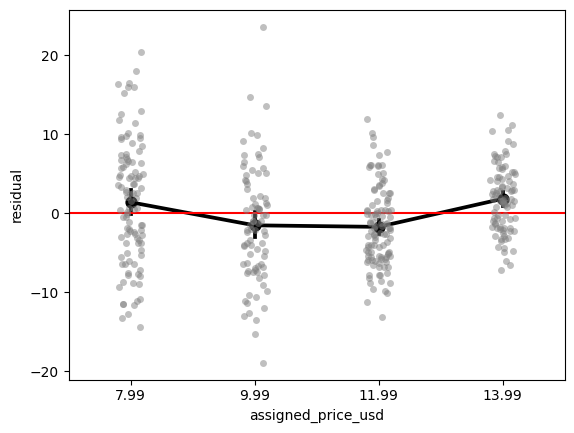

In [20]:
#1. residual plot fit_a
sns.stripplot(x=df_train['assigned_price_usd'], y=fit_a.resid, color='gray', alpha=0.5)
sns.pointplot(x=df_train['assigned_price_usd'], y=fit_a.resid, color='black')
plt.axhline(0, color='red')
plt.ylabel('residual')
plt.show()

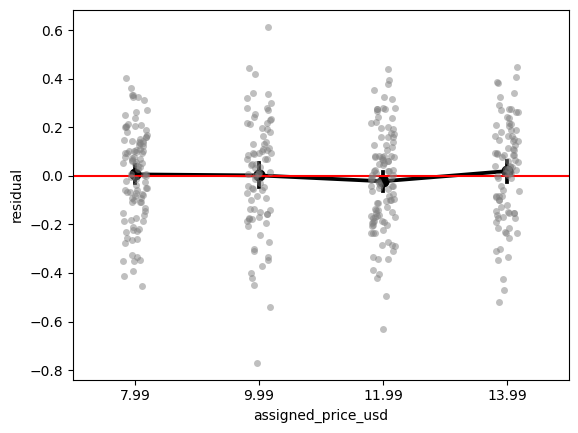

In [21]:
#1. residual plot fit_b
sns.stripplot(x=df_train['assigned_price_usd'], y=fit_b.resid, color='gray', alpha=0.5)
sns.pointplot(x=df_train['assigned_price_usd'], y=fit_b.resid, color='black')
plt.axhline(0, color='red')
plt.ylabel('residual')
plt.show()

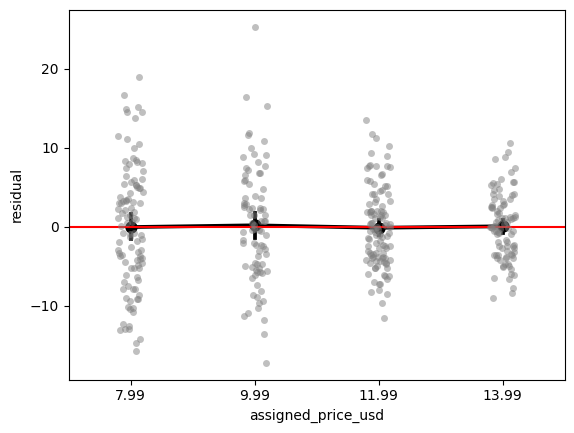

In [22]:
#1. residual plot fit_c
sns.stripplot(x=df_train['assigned_price_usd'], y=fit_c.resid, color='gray', alpha=0.5)
sns.pointplot(x=df_train['assigned_price_usd'], y=fit_c.resid, color='black')
plt.axhline(0, color='red')
plt.ylabel('residual')
plt.show()

**#2 Answer:** The model whose residuals are centered away from zero is model fit_a. Most price points aren't quite at zero, with prices 9.99 and 11.99 seeming to be the furthest away.

**#3 Answer:** The pattern seems to be U-shaped, indicating that the true fit might be a quadratic, not a linear.

In [23]:
#4 fit_a
fit_lin = fit_a.predict(df_test)
print(fit_lin)

0      19.199076
5      19.199076
10     26.156854
15     26.156854
20     40.072410
         ...    
455    40.072410
460    40.072410
465    26.156854
470    33.114632
475    26.156854
Length: 96, dtype: float64


In [24]:
#4 fit_a table
pd.DataFrame({
    'assigned_price_usd': df_test['assigned_price_usd'],
    'predicted_subscriptions_a': fit_lin
})

,assigned_price_usd,predicted_subscriptions_a
0,13.99,19.199076
5,13.99,19.199076
10,11.99,26.156854
15,11.99,26.156854
20,7.99,40.072410
...,...,...
455,7.99,40.072410
460,7.99,40.072410
465,11.99,26.156854
470,9.99,33.114632


In [25]:
#4 fit_b
non_log_b = np.exp(fit_b.predict(df_test))
print(non_log_b)

0      20.220158
5      20.220158
10     24.484139
15     24.484139
20     40.506133
         ...    
455    40.506133
460    40.506133
465    24.484139
470    30.703336
475    24.484139
Length: 96, dtype: float64


In [26]:
#4 table
pd.DataFrame({
    'assigned_price_usd': df_test['assigned_price_usd'],
    'predicted_subscriptions_b': non_log_b
})

,assigned_price_usd,predicted_subscriptions_b
0,13.99,20.220158
5,13.99,20.220158
10,11.99,24.484139
15,11.99,24.484139
20,7.99,40.506133
...,...,...
455,7.99,40.506133
460,7.99,40.506133
465,11.99,24.484139
470,9.99,30.703336


In [34]:
#4 fit_c
fit_quad = fit_c.predict(df_test)
print(fit_quad)

0      20.985079
5      20.985079
10     24.579855
15     24.579855
20     41.524717
         ...    
455    41.524717
460    41.524717
465    24.579855
470    31.426401
475    24.579855
Length: 96, dtype: float64


In [28]:
#4 table
pd.DataFrame({
    'assigned_price_usd': df_test['assigned_price_usd'],
    'predicted_subscriptions_b': fit_quad
})

,assigned_price_usd,predicted_subscriptions_b
0,13.99,20.985079
5,13.99,20.985079
10,11.99,24.579855
15,11.99,24.579855
20,7.99,41.524717
...,...,...
455,7.99,41.524717
460,7.99,41.524717
465,11.99,24.579855
470,9.99,31.426401


In [38]:
#5 Report each model's RMSE on `test`, the square root of the mean squared prediction error.
rmse_a =np.sqrt(np.mean((df_test['subscriptions_per_1000'] - fit_lin) ** 2)) #error = actual - predicted
rmse_b = np.sqrt(np.mean((df_test['subscriptions_per_1000'] - non_log_b) ** 2))
rmse_c = np.sqrt(np.mean((df_test['subscriptions_per_1000'] - fit_quad) ** 2))

# required scorecard output
scorecard = pd.DataFrame({
    'model': ['A lin', 'B log', 'C quad'],
    'test_RMSE': [rmse_a, rmse_b, rmse_c]
}).round(3)
scorecard

,model,test_RMSE
0,A lin,5.222
1,B log,5.125
2,C quad,4.952


**#6 Answer:** The model with the lowest test RMSE is model c with RMSE = 4.952

**#7 Answer:** The best two models in terms of RMSE are very similar, with only a difference of 0.173 (3.4% smaller than model b). 


In [41]:
((5.125-4.952)/(5.125)) * 100

3.3756097560975618

## Stage 6. Take each curve to \$15

The price test never charged \$15, so every prediction at \$15 comes from a model, not from the experiment.

- 1. At what price is model C's slope, your Stage 4 marginal effect, zero?
- 2. What does model C predict above that price?
- 3. Does that make economic sense for a subscription?
- 4. Make a table with each model's predicted subscriptions per 1,000 and revenue per 1,000 visitors at \$13.99 and at \$15.
- 5. Under each model, does moving from \$13.99 to \$15 raise or lower revenue per 1,000 visitors?
- 6. The test markets were charged the same four prices as the training markets. What can your Stage 5 scorecard tell you about which model predicts best at \$15?

**Output:** a scenario table.

#1. Model C (quadratic): $q_i = \gamma_0 + \gamma_1 \text{Price}_i + \gamma_2 \text{Price}_i^2 + e_i$
So, to find marginal effect, take the derivative WRT price = $ \gamma_1 + 2\gamma_2 \text{Price}_i$

In [46]:
#1. set equal to zero and solve
point1 = fit_c.params['assigned_price_usd']
point2 = fit_c.params['I(assigned_price_usd ** 2)']
vertex = -point1 / (2 * point2)
print(vertex)

15.200964998728574


**#1 Answer:** The marginal effect of model c is equal to zero when price is equal to 15.2 dollars

**#2 Answer:** Since the estimation of $\gamma_2$ is positive, the quadratic opens upward making the vertex of 15.2 a minimum. Therefore, it predicts that prices higher than 15.2 will yield higher subscriptions.

**#3 Answer:** No, this does not make sense economically. Typically, when prices increase, demand decreases. This model claims that as prices increase (after 15.2 dollars), demand will also increase.

In [56]:
#4 Scenario table of subs and revenue at prices 13.99 and 15 dollars
table = pd.DataFrame({'assigned_price_usd': [13.99, 15]})

table['fit_a'] = fit_a.predict(table)
table['fit_b'] = np.exp(fit_b.predict(table))   # change log back to subscriptions per 1,000
table['fit_c'] = fit_c.predict(table)

table['rev_a'] = table['assigned_price_usd'] * table['fit_a']
table['rev_b'] = table['assigned_price_usd'] * table['fit_b']
table['rev_c'] = table['assigned_price_usd'] * table['fit_c']

print(table)

   assigned_price_usd      fit_a      fit_b      fit_c       rev_a  \
0               13.99  19.199076  20.220158  20.985079  268.595072   
1               15.00  15.685398  18.545364  20.405431  235.280970   

        rev_b       rev_c  
0  282.880011  293.581256  
1  278.180460  306.081464  


**#5 Answer:** Increasing the price from 13.99 to 15 dollars decreases revenue for fit a (by approx. 32 dollars) and fit b (by approx. 4 dollars), while the revenue for fit c increases (by approx. 13 dollars).

**#6 Answer:** The scorecard can't tell us which model predicts best at 15 dollars, because the test markets were charged the same four prices as the train markets. The RMSEs can only measure the prices tested, it cannot predict non-tested prices, like 15 dollars. The models fit about equally well for the tested 13 price but diverge at $15 (15.7 to 20.4), so only a direct test at that price can tell us which is right.

## Stage 7. Recommendation to the vice president for growth and pricing

In one paragraph of about 150 words, cover:

- which demand curve the team should use for planning near the tested prices, and why;
- what a 1% higher price does to subscriptions near the tested prices;
- what your Stage 3 and Stage 6 revenue tables say about raising the price;
- what the price test can and cannot tell the team about \$15;
- the next price test you would run, and why.

Write for a manager who has not taken econometrics: say what the numbers mean for pricing, in plain words.

**Output:** the recommendation.

For planning near the tested prices, the team should use model b, the log-log curve. Model B demonstrates that higher prices equate to fewer subscriptions, following economic intuition (which model C failed to do, and model A had the highest RMSE, ruling them out). Fit B shows that a 1% increase in price is predicted to lower subscriptions by 1.24%. Since 1%<1.24%, the loss in subscriptions is larger than gain of the increase in price. The revenue was highest at 7.99 (about 331 dollars) and fell to about 294 at 13.99 (Stage 3), while at 15 dollars, two of three models predict lower revenue (Stage 6). The one model that predicts an increase at 15 dollars is the quadratic because it naturally turns upward after the local min. The price test never tested 15 dollars, so any estimate is a guess. We can be more confident in our predictions with the prices tesed. I would run a new randomized test that includes markets at 15 dollars (and beyond) to measure demand directly.